In [1]:
!pip install mysql-connector-python pandas numpy matplotlib seaborn

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import mysql.connector
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

print("CivicShield analysis environment is ready!")

CivicShield analysis environment is ready!


In [3]:
connection = mysql.connector.connect(
    host="localhost",
    user="root",
    password="Apex@2104",
    database="civicshield"
)

print("CivicShield MySQL connected!")

CivicShield MySQL connected!


In [4]:
cursor = connection.cursor()

cursor.execute("SHOW TABLES")

tables = cursor.fetchall()

print("Tables available in CivicShield:")

for table in tables:
    print("-", table[0])

cursor.close()

Tables available in CivicShield:
- flood_events
- population
- rainfall
- river_levels
- shelters


True

In [5]:
rainfall = pd.read_sql(
    "SELECT * FROM rainfall",
    connection
)

river_levels = pd.read_sql(
    "SELECT * FROM river_levels",
    connection
)

population = pd.read_sql(
    "SELECT * FROM population",
    connection
)

flood_events = pd.read_sql(
    "SELECT * FROM flood_events",
    connection
)

shelters = pd.read_sql(
    "SELECT * FROM shelters",
    connection
)

print("All tables loaded successfully!")

All tables loaded successfully!


C:\Users\Ommp Abinash\AppData\Local\Temp\ipykernel_9668\86198503.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  rainfall = pd.read_sql(
C:\Users\Ommp Abinash\AppData\Local\Temp\ipykernel_9668\86198503.py:6: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  river_levels = pd.read_sql(
C:\Users\Ommp Abinash\AppData\Local\Temp\ipykernel_9668\86198503.py:11: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  population = pd.read_sql(
C:\Users\Ommp Abinash\AppData\Local\Temp\ipykernel_9668\86198503.py:16: UserWarning: pandas only su

In [6]:
print("RAINFALL")
display(rainfall.head())

print("RIVER LEVELS")
display(river_levels.head())

print("POPULATION")
display(population.head())

print("HISTORICAL FLOODS")
display(flood_events.head())

print("SHELTERS")
display(shelters.head())

RAINFALL


,id,date,district,location,rainfall_mm
0,1,2026-09-01,Balasore,Nilagiri,120.5
1,2,2026-09-01,Balasore,Soro,95.2
2,3,2026-09-01,Balasore,Bhograi,145.8
3,4,2021-02-07,Angul,Angul Test Station 2,7.0
4,5,2021-03-16,Balangir,Balangir Test Station 3,14.0


RIVER LEVELS


,id,date,river,location,water_level_m,danger_level_m
0,1,2026-09-01,Subarnarekha,Balasore,8.20,9.5
1,2,2026-09-02,Subarnarekha,Balasore,9.10,9.5
2,3,2021-06-12,Brahmani,Angul,2.13,6.0
3,4,2021-06-23,Baitarani,Balangir,2.26,6.0
4,5,2021-07-04,Subarnarekha,Balasore,2.39,6.0


POPULATION


,id,district,location,population,area_km2
0,1,Balasore,Nilagiri,25000,120.0
1,2,Balasore,Soro,32000,150.0
2,3,Balasore,Bhograi,41000,180.0
3,4,Angul,Angul Sample Area 2,12919,27.0
4,5,Balangir,Balangir Sample Area 3,20838,44.0


HISTORICAL FLOODS


,id,date,district,location,severity,affected_population
0,1,2024-08-15,Balasore,Nilagiri,3,5000
1,2,2025-07-20,Balasore,Soro,4,12000
2,3,2025-08-05,Balasore,Bhograi,5,18000
3,4,2021-06-24,Angul,Angul Sample Area 2,2,237
4,5,2021-07-17,Balangir,Balangir Sample Area 3,3,374


SHELTERS


,id,district,location,capacity,available_capacity
0,1,Balasore,Nilagiri,1000,850
1,2,Balasore,Soro,1500,1200
2,3,Balasore,Bhograi,2000,1600
3,4,Angul,Angul Sample Shelter 2,153,44
4,5,Balangir,Balangir Sample Shelter 3,206,119


In [7]:
dataframes = {
    "rainfall": rainfall,
    "river_levels": river_levels,
    "population": population,
    "flood_events": flood_events,
    "shelters": shelters
}

for name, df in dataframes.items():
    print(f"\n--- {name.upper()} ---")
    print("Rows:", len(df))
    print("Columns:", df.columns.tolist())
    print("Missing values:")
    print(df.isnull().sum())


--- RAINFALL ---
Rows: 5000
Columns: ['id', 'date', 'district', 'location', 'rainfall_mm']
Missing values:
id             0
date           0
district       0
location       0
rainfall_mm    0
dtype: int64

--- RIVER_LEVELS ---
Rows: 1002
Columns: ['id', 'date', 'river', 'location', 'water_level_m', 'danger_level_m']
Missing values:
id                0
date              0
river             0
location          0
water_level_m     0
danger_level_m    0
dtype: int64

--- POPULATION ---
Rows: 303
Columns: ['id', 'district', 'location', 'population', 'area_km2']
Missing values:
id            0
district      0
location      0
population    0
area_km2      0
dtype: int64

--- FLOOD_EVENTS ---
Rows: 303
Columns: ['id', 'date', 'district', 'location', 'severity', 'affected_population']
Missing values:
id                     0
date                   0
district               0
location               0
severity               0
affected_population    0
dtype: int64

--- SHELTERS ---
Rows: 153
Colum

In [8]:
rainfall["date"] = pd.to_datetime(
    rainfall["date"], errors="coerce"
)

rainfall["rainfall_mm"] = pd.to_numeric(
    rainfall["rainfall_mm"], errors="coerce"
)

rainfall["location"] = (
    rainfall["location"].astype("string").str.strip()
)

rainfall = rainfall.dropna(
    subset=["date", "location", "rainfall_mm"]
)

print("Rainfall data cleaned.")
display(rainfall.head())

Rainfall data cleaned.


,id,date,district,location,rainfall_mm
0,1,2026-09-01,Balasore,Nilagiri,120.5
1,2,2026-09-01,Balasore,Soro,95.2
2,3,2026-09-01,Balasore,Bhograi,145.8
3,4,2021-02-07,Angul,Angul Test Station 2,7.0
4,5,2021-03-16,Balangir,Balangir Test Station 3,14.0


In [9]:
print("Rainfall Summary")

display(rainfall["rainfall_mm"].describe())

print("Total rainfall observations:", len(rainfall))
print("Number of locations:", rainfall["location"].nunique())
print("Earliest date:", rainfall["date"].min())
print("Latest date:", rainfall["date"].max())

Rainfall Summary


count    5000.000000
mean       47.323500
std        45.775033
min         0.000000
25%        18.000000
50%        35.000000
75%        51.000000
max       196.000000
Name: rainfall_mm, dtype: float64

Total rainfall observations: 5000
Number of locations: 33
Earliest date: 2021-01-01 00:00:00
Latest date: 2026-09-01 00:00:00


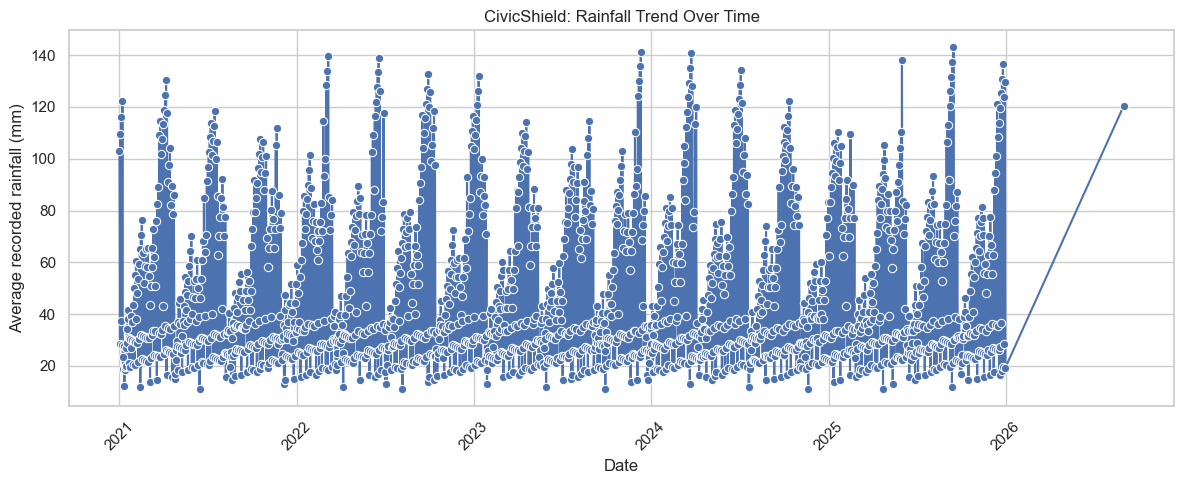

In [10]:
rainfall_daily = (
    rainfall.groupby("date", as_index=False)
    ["rainfall_mm"].mean()
    .sort_values("date")
)

plt.figure(figsize=(12, 5))

sns.lineplot(
    data=rainfall_daily,
    x="date",
    y="rainfall_mm",
    marker="o"
)

plt.title("CivicShield: Rainfall Trend Over Time")
plt.xlabel("Date")
plt.ylabel("Average recorded rainfall (mm)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

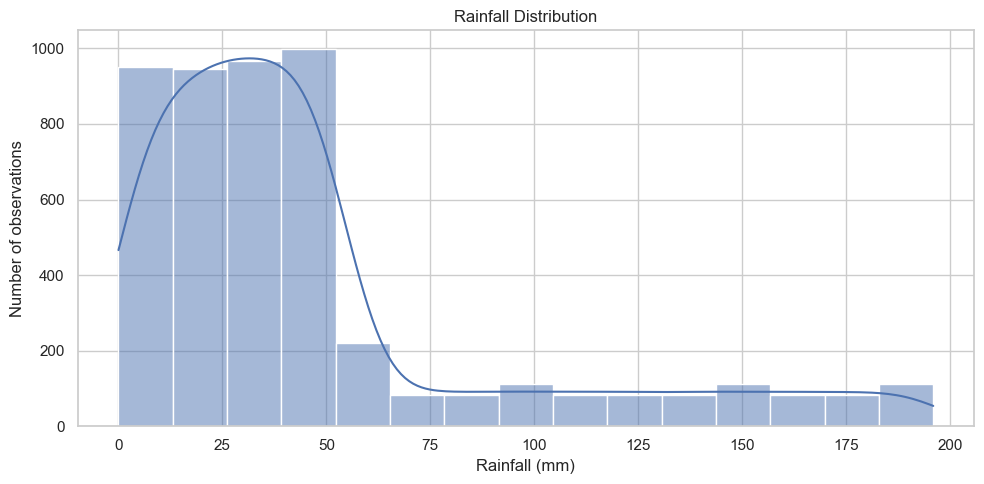

In [11]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=rainfall,
    x="rainfall_mm",
    bins=15,
    kde=True
)

plt.title("Rainfall Distribution")
plt.xlabel("Rainfall (mm)")
plt.ylabel("Number of observations")
plt.tight_layout()
plt.show()

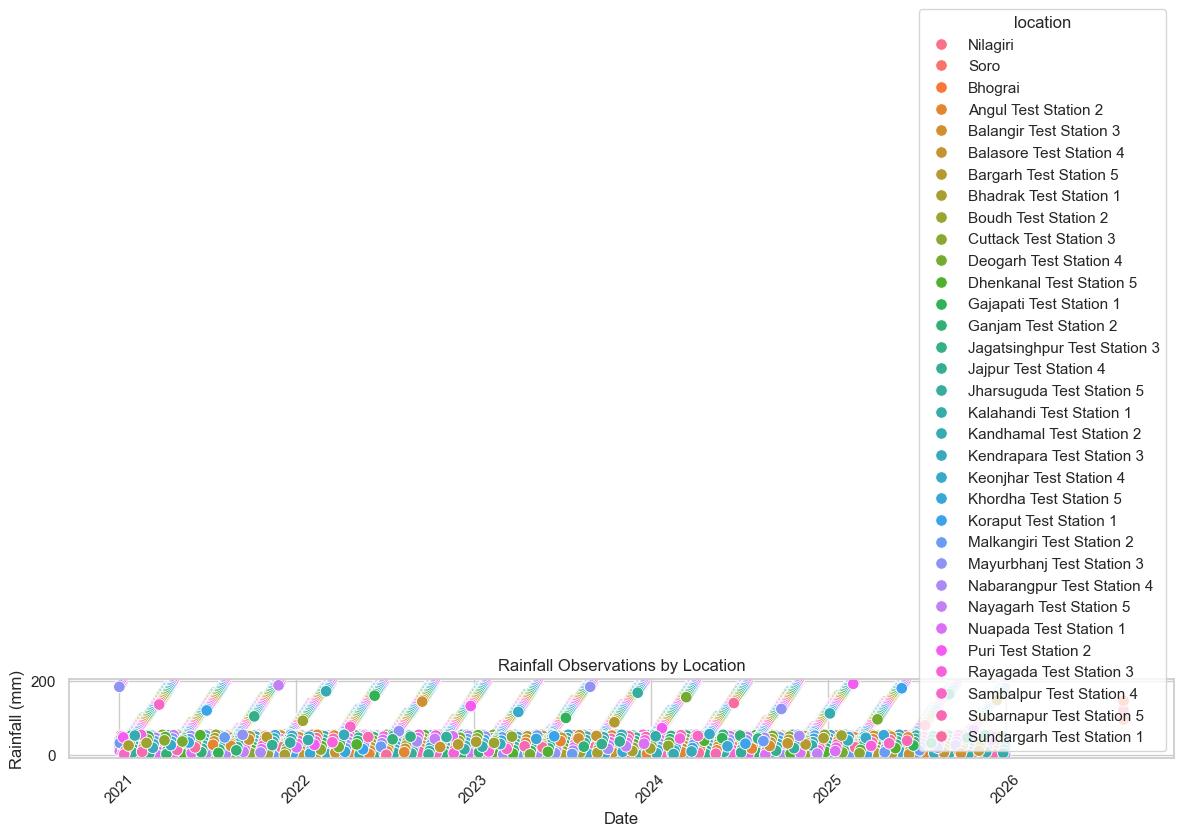

In [12]:
plt.figure(figsize=(12, 5))

sns.scatterplot(
    data=rainfall,
    x="date",
    y="rainfall_mm",
    hue="location",
    s=70
)

plt.title("Rainfall Observations by Location")
plt.xlabel("Date")
plt.ylabel("Rainfall (mm)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

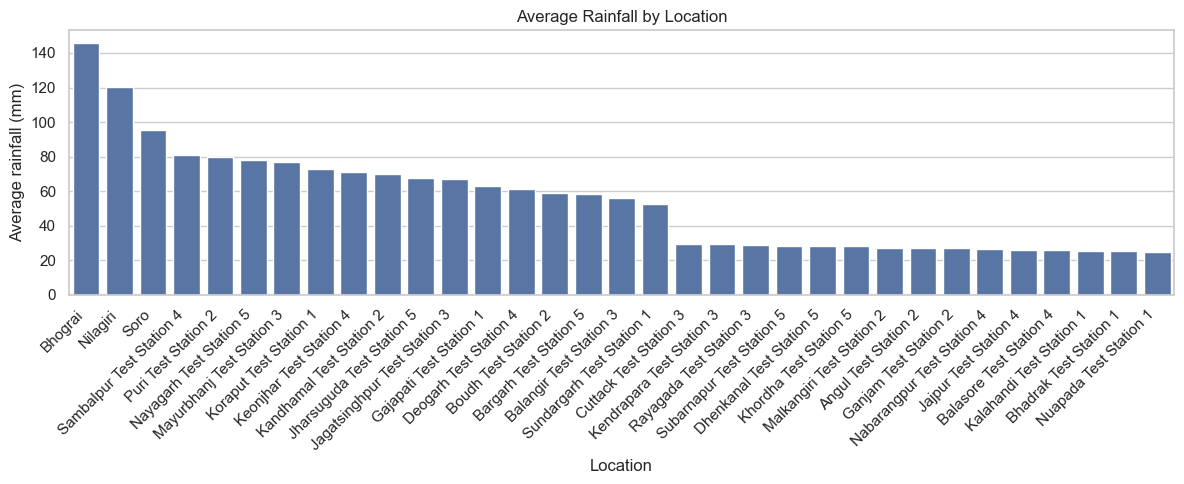

In [13]:
rainfall_by_location = (
    rainfall.groupby("location", as_index=False)
    ["rainfall_mm"].mean()
    .sort_values("rainfall_mm", ascending=False)
)

plt.figure(figsize=(12, 5))

sns.barplot(
    data=rainfall_by_location,
    x="location",
    y="rainfall_mm"
)

plt.title("Average Rainfall by Location")
plt.xlabel("Location")
plt.ylabel("Average rainfall (mm)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

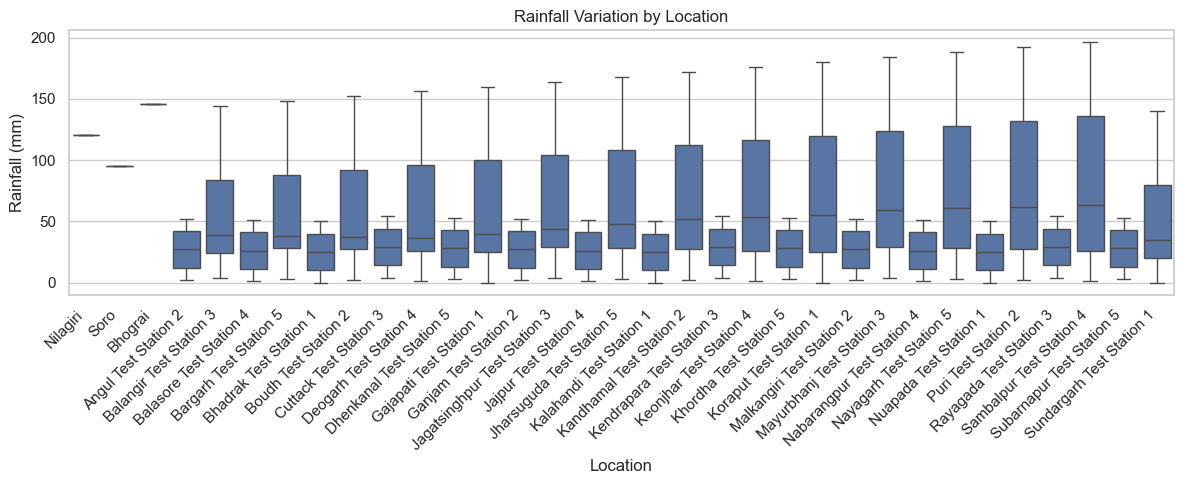

In [14]:
plt.figure(figsize=(12, 5))

sns.boxplot(
    data=rainfall,
    x="location",
    y="rainfall_mm"
)

plt.title("Rainfall Variation by Location")
plt.xlabel("Location")
plt.ylabel("Rainfall (mm)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

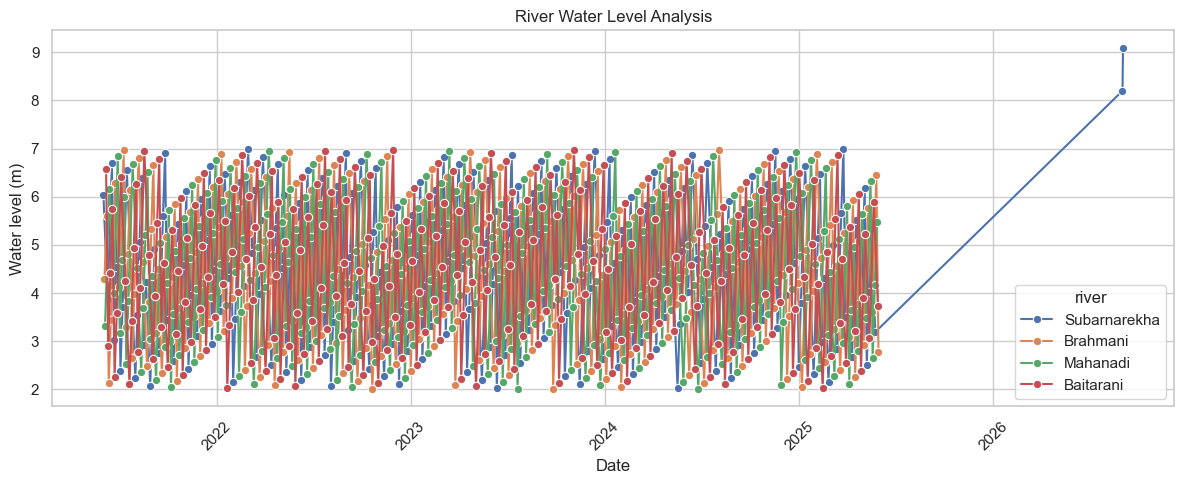

In [15]:
river_levels["date"] = pd.to_datetime(
    river_levels["date"], errors="coerce"
)

river_levels["water_level_m"] = pd.to_numeric(
    river_levels["water_level_m"], errors="coerce"
)

river_levels["danger_level_m"] = pd.to_numeric(
    river_levels["danger_level_m"], errors="coerce"
)

river_clean = river_levels.dropna(
    subset=["date", "water_level_m"]
).sort_values("date")

plt.figure(figsize=(12, 5))

sns.lineplot(
    data=river_clean,
    x="date",
    y="water_level_m",
    hue="river",
    marker="o"
)

# Add a danger-level reference only if a single comparable
# danger level is defined for the plotted observations.
danger_levels = river_clean["danger_level_m"].dropna().unique()

if len(danger_levels) == 1:
    plt.axhline(
        danger_levels[0],
        linestyle="--",
        label="Danger level"
    )

plt.title("River Water Level Analysis")
plt.xlabel("Date")
plt.ylabel("Water level (m)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [16]:
rain_daily = (
    rainfall.groupby(["date", "location"], as_index=False)
    ["rainfall_mm"].mean()
)

river_daily = (
    river_clean.groupby(["date", "location"], as_index=False)
    .agg(water_level_m=("water_level_m", "mean"))
)

matched = rain_daily.merge(
    river_daily,
    on=["date", "location"],
    how="inner"
)

print("Matched observations:", len(matched))

if not matched.empty:
    plt.figure(figsize=(10, 6))

    sns.scatterplot(
        data=matched,
        x="rainfall_mm",
        y="water_level_m"
    )

    plt.title("Rainfall vs River Water Level")
    plt.xlabel("Rainfall (mm)")
    plt.ylabel("River water level (m)")
    plt.tight_layout()
    plt.show()
else:
    print(
        "No matching date-location observations. "
        "Check the location names and dates."
    )

Matched observations: 0
No matching date-location observations. Check the location names and dates.


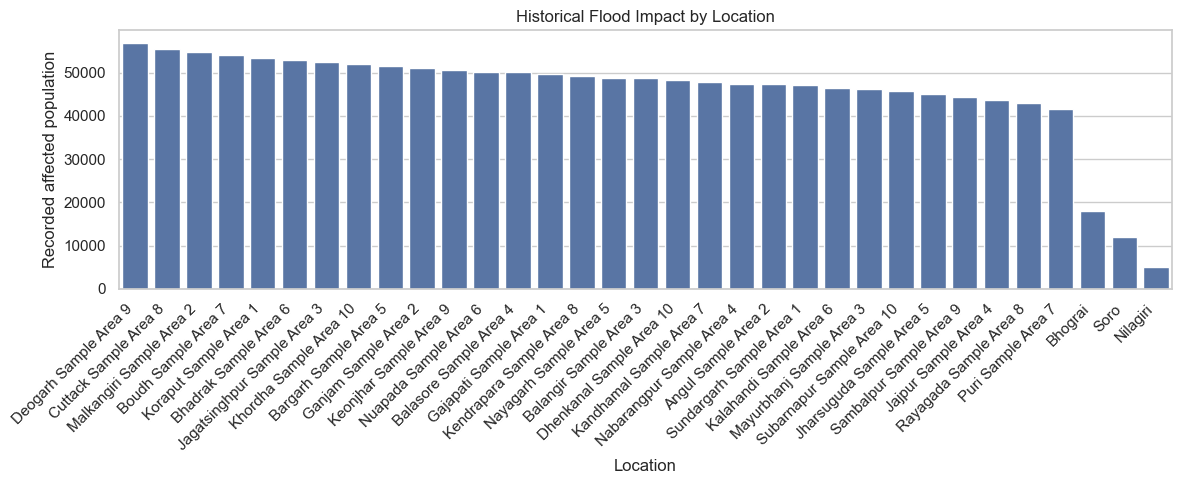

In [17]:
floods = flood_events.copy()

if not floods.empty and "affected_population" in floods.columns:
    floods["affected_population"] = pd.to_numeric(
        floods["affected_population"], errors="coerce"
    )

    impact = (
        floods.groupby("location", as_index=False)
        ["affected_population"].sum()
        .sort_values("affected_population", ascending=False)
    )

    plt.figure(figsize=(12, 5))

    sns.barplot(
        data=impact,
        x="location",
        y="affected_population"
    )

    plt.title("Historical Flood Impact by Location")
    plt.xlabel("Location")
    plt.ylabel("Recorded affected population")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("No historical flood impact data is available.")

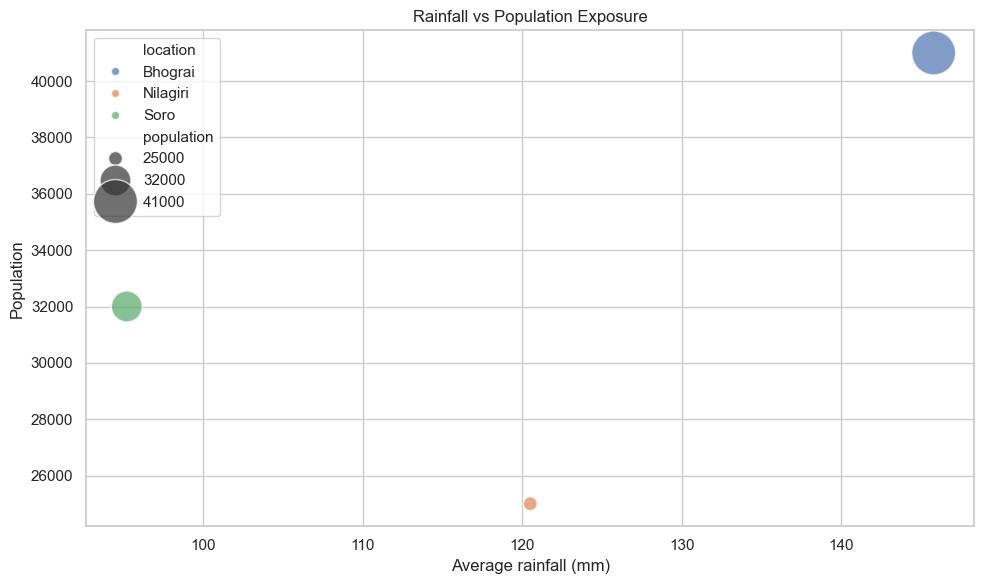

In [18]:
pop = population.copy()

pop["population"] = pd.to_numeric(
    pop["population"], errors="coerce"
)

rain_loc = (
    rainfall.groupby("location", as_index=False)
    ["rainfall_mm"].mean()
    .rename(columns={"rainfall_mm": "avg_rainfall_mm"})
)

pop_loc = (
    pop.dropna(subset=["population"])
    .groupby("location", as_index=False)
    ["population"].sum()
)

bubble = rain_loc.merge(
    pop_loc,
    on="location",
    how="inner"
)

if not bubble.empty:
    plt.figure(figsize=(10, 6))

    sns.scatterplot(
        data=bubble,
        x="avg_rainfall_mm",
        y="population",
        size="population",
        sizes=(100, 1000),
        hue="location",
        alpha=0.7
    )

    plt.title("Rainfall vs Population Exposure")
    plt.xlabel("Average rainfall (mm)")
    plt.ylabel("Population")
    plt.tight_layout()
    plt.show()
else:
    print("No matching locations in rainfall and population data.")

In [19]:
numeric_data = matched[
    ["rainfall_mm", "water_level_m"]
].copy()

if len(numeric_data) >= 2:
    correlation = numeric_data.corr(numeric_only=True)

    plt.figure(figsize=(7, 5))

    sns.heatmap(
        correlation,
        annot=True,
        cmap="coolwarm",
        vmin=-1,
        vmax=1,
        fmt=".2f"
    )

    plt.title("Rainfall and River-Level Correlation")
    plt.tight_layout()
    plt.show()
else:
    print(
        "Not enough matched observations for correlation analysis."
    )

Not enough matched observations for correlation analysis.


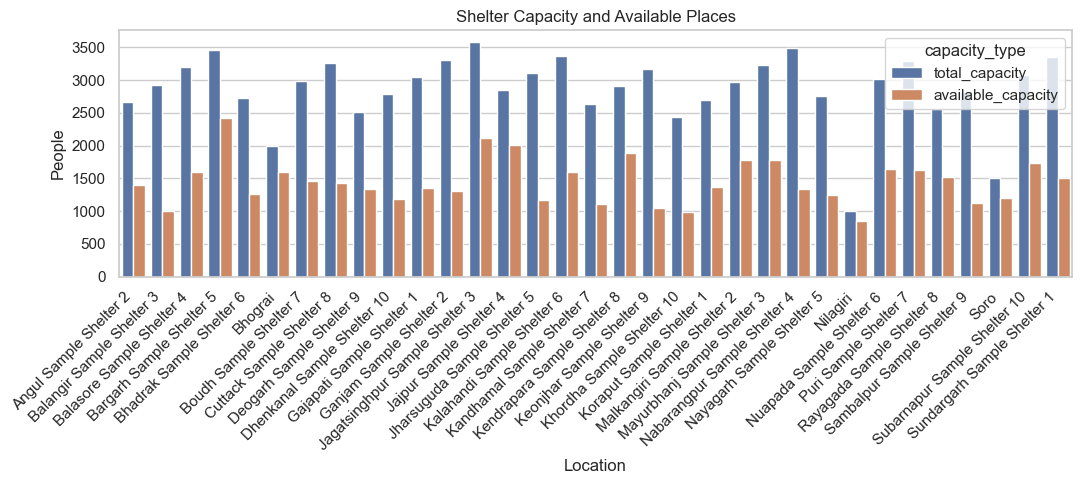

In [20]:
shelter_data = shelters.copy()

if (
    not shelter_data.empty
    and "capacity" in shelter_data.columns
    and "available_capacity" in shelter_data.columns
):
    shelter_data["capacity"] = pd.to_numeric(
        shelter_data["capacity"], errors="coerce"
    )
    shelter_data["available_capacity"] = pd.to_numeric(
        shelter_data["available_capacity"], errors="coerce"
    )

    shelter_summary = (
        shelter_data.groupby("location", as_index=False)
        .agg(
            total_capacity=("capacity", "sum"),
            available_capacity=("available_capacity", "sum")
        )
    )

    plt.figure(figsize=(11, 5))

    shelter_plot = shelter_summary.melt(
        id_vars="location",
        value_vars=["total_capacity", "available_capacity"],
        var_name="capacity_type",
        value_name="people"
    )

    sns.barplot(
        data=shelter_plot,
        x="location",
        y="people",
        hue="capacity_type"
    )

    plt.title("Shelter Capacity and Available Places")
    plt.xlabel("Location")
    plt.ylabel("People")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("Shelter capacity data is unavailable or incomplete.")